# 01 - Data preprocessing

Loads the raw crash dataset (10,000 rows x 46 columns), reports missing values, imputes them (weather columns: forward/back-fill in time order, then median; categoricals: mode), derives `Duration_Minutes`, and caps outliers with the IQR rule (capping, not row removal).

**Run first.** Input: `US A 10000.csv`. Output: `outputs/Processed_Data/cleaned_dataset.csv`, `outputs/Figures/missing_values_raw.png`.

> **[PATCH-1]** is the only change to the original logic in this notebook (marked in-cell); see README.md.

*Source: `CODE/01_data_preprocessing.py`*

## 0. Environment

In [1]:
import sys, importlib
print("Python", sys.version.split()[0])
for pkg in ['pandas', 'numpy', 'matplotlib']:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:<12}{getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"{pkg:<12}NOT INSTALLED")

Python 3.13.18
pandas      2.2.3
numpy       2.1.3
matplotlib  3.10.0


## 1. Imports and configuration

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # display only (e.g. seaborn palette notice)
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")  # display only (pandas 3 select_dtypes notice)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

np.random.seed(RANDOM_SEED)

## 2. Functions (verbatim from the original script)

### `load_raw_data()`

In [3]:
def load_raw_data(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    print(f"[LOAD] Raw dataset shape: {df.shape}")
    return df

### `report_missing_values()`

In [4]:
def report_missing_values(df: pd.DataFrame, save_path: str = None) -> pd.Series:
    missing = df.isna().sum()
    missing_pct = (missing / len(df) * 100).round(2)
    report = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
    report = report[report["missing_count"] > 0].sort_values("missing_pct", ascending=False)
    print("[MISSING VALUES]")
    print(report)

    if save_path:
        fig, ax = plt.subplots(figsize=(10, 6))
        if not report.empty:
            ax.barh(report.index, report["missing_pct"])
            ax.set_xlabel("Missing (%)")
            ax.set_title("Missing Values by Column (Raw Dataset)")
            plt.tight_layout()
        plt.savefig(save_path, dpi=150)
        plt.close()
    return report

### `handle_missing_values()`

Numeric columns: median imputation (robust to skew/outliers).

In [5]:
def handle_missing_values(df: pd.DataFrame) -> pd.DataFrame:
    """
    Numeric columns: median imputation (robust to skew/outliers).
    Categorical columns: mode imputation, fallback to 'Unknown'.
    Weather-related numerics: forward/backward fill within sorted time
    order first (weather is temporally correlated), then median as backstop.
    """
    df = df.copy()

    numeric_cols = df.select_dtypes(include=[np.number]).columns
    categorical_cols = df.select_dtypes(include=["object"]).columns

    weather_numeric = [
        c for c in ["Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
                     "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
        if c in df.columns
    ]

    if "Start_Time" in df.columns:
        df["Start_Time"] = pd.to_datetime(df["Start_Time"], errors="coerce")
        df = df.sort_values("Start_Time")

    for col in weather_numeric:
        df[col] = df[col].ffill().bfill()

    for col in numeric_cols:
        if df[col].isna().any():
            df[col] = df[col].fillna(df[col].median())

    # [PATCH-1] Columns that are 100% missing (End_Lat, End_Lng) have an undefined median, so they
    # stayed NaN and later crashed GradientBoosting / AdaBoost / MLP (they reject NaN input).
    # Thesis Chapter 3, Sec. 3.6.1 states such columns are filled with the constant placeholder 0.
    fully_missing = [c for c in numeric_cols if df[c].isna().all()]
    for col in fully_missing:
        df[col] = 0.0
    if fully_missing:
        print(f"[PATCH-1] Fully-missing columns filled with constant 0: {fully_missing}")

    for col in categorical_cols:
        if df[col].isna().any():
            mode_val = df[col].mode()
            fill_val = mode_val.iloc[0] if not mode_val.empty else "Unknown"
            df[col] = df[col].fillna(fill_val)

    print(f"[MISSING] Remaining NaNs after imputation: {df.isna().sum().sum()}")
    return df

### `cap_outliers_iqr()`

Caps (winsorizes) numeric outliers using the IQR rule instead of

In [6]:
def cap_outliers_iqr(df: pd.DataFrame, columns: list, factor: float = 1.5) -> pd.DataFrame:
    """
    Caps (winsorizes) numeric outliers using the IQR rule instead of
    removing rows, to preserve sample size and all original records.
    """
    df = df.copy()
    for col in columns:
        if col not in df.columns:
            continue
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - factor * iqr
        upper = q3 + factor * iqr
        n_capped = ((df[col] < lower) | (df[col] > upper)).sum()
        df[col] = df[col].clip(lower=lower, upper=upper)
        if n_capped > 0:
            print(f"[OUTLIERS] Capped {n_capped} values in '{col}' to [{lower:.2f}, {upper:.2f}]")
    return df

### `compute_duration_minutes()`

In [7]:
def compute_duration_minutes(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if "Start_Time" in df.columns and "End_Time" in df.columns:
        df["Start_Time"] = pd.to_datetime(df["Start_Time"], errors="coerce")
        df["End_Time"] = pd.to_datetime(df["End_Time"], errors="coerce")
        df["Duration_Minutes"] = (df["End_Time"] - df["Start_Time"]).dt.total_seconds() / 60.0
        df["Duration_Minutes"] = df["Duration_Minutes"].clip(lower=0)
    return df

### `main()`

In [8]:
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    os.makedirs(FIGURES_DIR, exist_ok=True)
    os.makedirs(f"{OUTPUT_DIR}/Processed_Data", exist_ok=True)

    df = load_raw_data(RAW_DATA_PATH)

    report_missing_values(df, save_path=f"{FIGURES_DIR}/missing_values_raw.png")

    df = handle_missing_values(df)
    df = compute_duration_minutes(df)

    outlier_candidates = [
        "Distance(mi)", "Temperature(F)", "Wind_Chill(F)", "Humidity(%)",
        "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)",
        "Precipitation(in)", "Duration_Minutes",
    ]
    df = cap_outliers_iqr(df, outlier_candidates)

    out_path = f"{OUTPUT_DIR}/Processed_Data/cleaned_dataset.csv"
    df.to_csv(out_path, index=False)
    print(f"[SAVE] Cleaned dataset -> {out_path}  shape={df.shape}")

## 3. Run

In [9]:
main()

[LOAD] Raw dataset shape: (10000, 46)
[MISSING VALUES]
                   missing_count  missing_pct
End_Lat                    10000       100.00
End_Lng                    10000       100.00
Precipitation(in)           8877        88.77
Wind_Chill(F)               8574        85.74
Wind_Speed(mph)             1774        17.74
Humidity(%)                  124         1.24
Visibility(mi)                96         0.96
Temperature(F)                85         0.85
Weather_Condition             77         0.77
Pressure(in)                  35         0.35
Weather_Timestamp             31         0.31
Wind_Direction                31         0.31
Timezone                       1         0.01
Zipcode                        1         0.01
Airport_Code                   1         0.01
[PATCH-1] Fully-missing columns filled with constant 0: ['End_Lat', 'End_Lng']
[MISSING] Remaining NaNs after imputation: 0
[OUTLIERS] Capped 48 values in 'Distance(mi)' to [-0.01, 0.03]
[OUTLIERS] Capped 29 v

## 4. Inspect the result

In [10]:
cleaned = pd.read_csv(f"{OUTPUT_DIR}/Processed_Data/cleaned_dataset.csv")
print("Cleaned shape        :", cleaned.shape)
print("NaN cells remaining  :", int(cleaned.isna().sum().sum()))
cleaned[["Start_Time", "Severity", "Distance(mi)", "Temperature(F)", "Visibility(mi)", "Duration_Minutes"]].head()

Cleaned shape        : (10000, 47)
NaN cells remaining  : 0


,Start_Time,Severity,Distance(mi),Temperature(F),Visibility(mi),Duration_Minutes
0,2016-02-08 05:46:00,3,0.01,36.9,10.0,67.95
1,2016-02-08 06:07:59,2,0.01,37.9,10.0,30.00
2,2016-02-08 06:49:27,2,0.01,36.0,10.0,30.00
3,2016-02-08 07:23:34,3,0.01,35.1,10.0,30.00
4,2016-02-08 07:39:07,2,0.01,36.0,10.0,30.00


Number of distinct values in each IQR-capped column after capping:

In [11]:
capped_cols = ["Distance(mi)", "Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
               "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)", "Duration_Minutes"]
cleaned[capped_cols].nunique().to_frame("distinct_values_after_capping")

,distinct_values_after_capping
Distance(mi),3
Temperature(F),236
Wind_Chill(F),47
Humidity(%),93
Pressure(in),91
Visibility(mi),1
Wind_Speed(mph),19
Precipitation(in),1
Duration_Minutes,689


### Missing-value figure produced by `report_missing_values()`

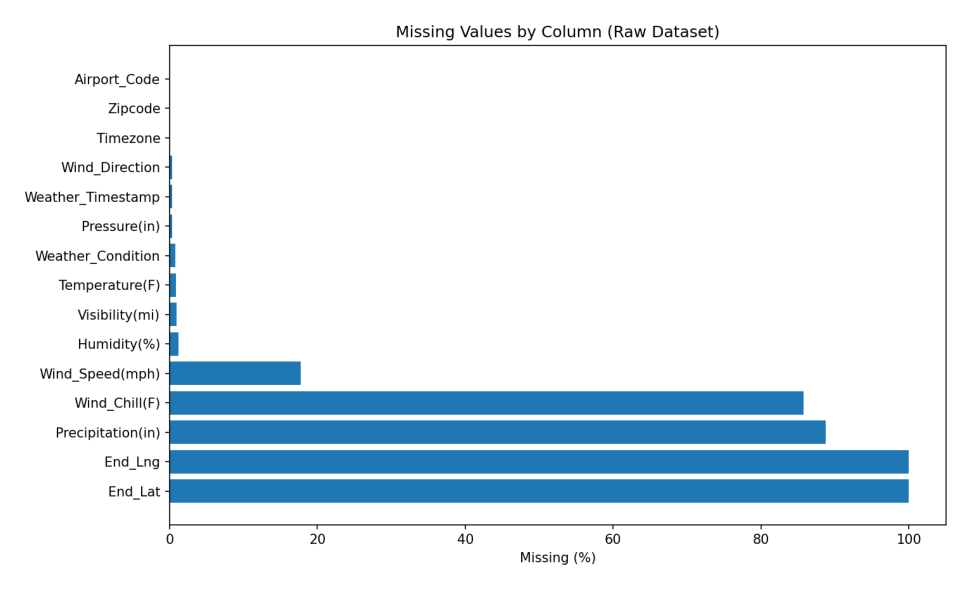

In [12]:
import matplotlib.pyplot as plt

def show_image(path, title=None, figsize=(11, 6)):
    """Display a PNG file inline."""
    img = plt.imread(path)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title, fontsize=11)
    plt.tight_layout()
    plt.show()

show_image(f"{FIGURES_DIR}/missing_values_raw.png", figsize=(10, 6))